# Lab 03: Phân Tích Cảm Xúc & Tinh Chỉnh Mô Hình Phân Loại Văn Bản Với Hugging Face
> **Kiến trúc:** Clean Architecture & Modular `src/` (Tự động nhận diện chạy mượt mà trên cả máy cục bộ có GPU RTX 2050 và Kaggle GPU Tesla T4)  
> **Mô hình & Hệ sinh thái:** Hugging Face `transformers` (`DistilBERT`), `datasets`, `evaluate`, `accelerate`  
> **Mục tiêu:** Thực hiện Exercise 1 (Inference Pipeline & Tokenization thủ công) và Exercise 2 (Finetuning DistilBERT cho Binary Text Classification trên `imdb`, vượt mốc Accuracy & Macro F1 >= 85.0%).

---

### Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai Đoạn (Phase) | Nội Dung Chi Tiết (Core Description) | Module Triển Khai | Sản Phẩm Đầu Ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Import** | Cấu hình thiết bị tính toán (CUDA/CPU), cố định seed 42 và nạp các thư viện Hugging Face cùng module `src/` | `transformers`, `torch` | Thông số môi trường thực thi, Device & Seed |
| **2** | **Exercise 1: Pipeline Inference** | Phân tích cảm xúc câu văn mẫu sử dụng pre-trained pipeline từ Hugging Face Hub | `transformers.pipeline` | Nhãn cảm xúc dự đoán (`POSITIVE`/`NEGATIVE`) và điểm tin cậy |
| **3** | **Exercise 1: Tokenizer & Forward Pass** | Khám phá cơ chế Tokenizer, cấu trúc tensor `input_ids`, `attention_mask` và tính Softmax thủ công | `AutoTokenizer`, `AutoModel` | Shape tensor, danh sách subword tokens, xác suất Softmax |
| **4** | **Exercise 2: Nạp Dataset & Phân Tầng** | Tải bộ dữ liệu `stanfordnlp/imdb` nhị phân, chia tập Train/Val/Test có kiểm soát chống rò rỉ dữ liệu | `datasets.load_dataset` | `DatasetDict` chuẩn hóa (`train`, `validation`, `test`) |
| **5** | **Exercise 2: Khám Phá Dữ Liệu (Text EDA)** | Phân tích phân bố nhãn, độ dài ký tự và số lượng từ trong bài đánh giá phim | `pandas`, `src.datasets` | Bảng thống kê độ dài từ `outputs/eda/tables/eda_train_stats.csv` |
| **6** | **Exercise 2: Tiền Xử Lý & Dynamic Padding** | Làm sạch thẻ HTML, mã hóa văn bản theo batch kết hợp `DataCollatorWithPadding` | `AutoTokenizer`, `DataCollator` | `tokenized_datasets` với độ dài linh hoạt theo batch |
| **7** | **Cổng Sanity Overfit 1 Batch (TDD Gate)** | Huấn luyện ép overfit 1 mini-batch (8 mẫu) kéo loss về sát 0 để chứng minh mô hình có khả năng học | `src.training.trainer` | Sanity Overfit Test PASSED (Final Loss < 0.05) |
| **8** | **Huấn Luyện Tinh Chỉnh (Finetuning)** | Thiết lập `TrainingArguments` và kích hoạt `Trainer` finetune mô hình DistilBERT kết hợp FP16 | `Trainer`, `TrainingArguments` | Trọng số `outputs/checkpoints/finetuned_distilbert` |
| **9** | **Đánh Giá Hiệu Năng & Ma Trận Nhầm Lẫn** | Đánh giá độc lập trên tập Test (Accuracy, Macro F1, Precision, Recall) và vẽ biểu đồ Confusion Matrix | `evaluate`, `seaborn` | `outputs/predictions/confusion_matrix.png`, `outputs/test_metrics.json` |
| **10** | **Kiểm Chứng Suy Luận & Đóng Gói Artifacts** | Nạp lại checkpoint đã finetune, kiểm chứng suy luận trên câu mới và nén toàn bộ artifacts | `src.models`, `shutil` | File nén lưu trữ `outputs_lab03.zip` |


## 1. Thiết Lập Môi Trường & Nạp Modules Từ `src/`
> Cấu hình đường dẫn hệ thống, kiểm tra phiên bản các thư viện nền tảng (`transformers`, `datasets`, `evaluate`, `torch`), cố định seed 42 để đảm bảo tính tái lập 100% theo hiến pháp `AGENTS.md`.


In [4]:
import os
import sys
import shutil
import json
import re
from importlib.metadata import version
from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nạp module src (hỗ trợ cả Kaggle và Local workspace)
current_dir = Path(".").resolve()
if (current_dir.parent / "src").exists():
    sys.path.insert(0, str(current_dir.parent))
elif Path("labs/lab03").exists():
    sys.path.insert(0, str(Path(".").resolve()))

from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    set_seed
)
from datasets import load_dataset, DatasetDict
import evaluate

# Cố định hạt giống ngẫu nhiên
RANDOM_SEED = 42
set_seed(RANDOM_SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[DEVICE] Thiết bị tính toán: {DEVICE}")
if torch.cuda.is_available():
    print(f"[SEED] Hạt giống ngẫu nhiên: {RANDOM_SEED}")
    print(f"[VERSIONS] PyTorch: {torch.__version__} | Transformers: {version('transformers')}")
    print(f"[VERSIONS] PyTorch: {torch.__version__} | Transformers: {version('transformers')}")


[DEVICE] Thiết bị tính toán: cuda
[SEED] Hạt giống ngẫu nhiên: 42
[VERSIONS] PyTorch: 2.6.0+cu124 | Transformers: 5.20.2
[VERSIONS] PyTorch: 2.6.0+cu124 | Transformers: 5.20.2


## 2. Exercise 1: Phân Tích Cảm Xúc Bằng Hugging Face Pipeline
> Tải và sử dụng mô hình tiền huấn luyện chuyên biệt cho bài toán Sentiment Analysis (`distilbert-base-uncased-finetuned-sst-2-english`) từ Hugging Face Hub thông qua hàm cấp cao `pipeline`.


In [6]:
# 1. Khởi tạo pipeline phân tích cảm xúc từ pre-trained model
model_name_exercise1 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
sentiment_pipeline = pipeline("sentiment-analysis", model=model_name_exercise1, device=0 if torch.cuda.is_available() else -1)

# 2. Câu văn mẫu kiểm thử cảm xúc
sample_sentences = [
    "This movie was an absolute masterpiece with breathtaking visual effects and stellar performances!",
    "The plot was painfully slow, predictable, and the acting felt completely wooden."
]

print("--- Kết Quả Dự Đoán Bằng Pipeline ---")
for text in sample_sentences:
    result = sentiment_pipeline(text)[0]
    print(f"Văn bản: {text}")
    print(f"-> Dự đoán: {result['label']} (Độ tin cậy: {result['score'] * 100:.2f}%)\n")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

--- Kết Quả Dự Đoán Bằng Pipeline ---
Văn bản: This movie was an absolute masterpiece with breathtaking visual effects and stellar performances!
-> Dự đoán: POSITIVE (Độ tin cậy: 99.99%)

Văn bản: The plot was painfully slow, predictable, and the acting felt completely wooden.
-> Dự đoán: NEGATIVE (Độ tin cậy: 99.98%)



## 3. Exercise 1: Khám Phá Tokenizer & Thực Hiện Forward Pass Thủ Công
> Tách nhỏ quy trình pipeline: Sử dụng `AutoTokenizer` để chuyển câu văn thành chuỗi số nguyên (`input_ids`, `attention_mask`), sau đó đưa qua `AutoModelForSequenceClassification` để tính hàm kích hoạt Softmax thủ công.


In [7]:
# 1. Tải Tokenizer và Model tương ứng
tokenizer_ex1 = AutoTokenizer.from_pretrained(model_name_exercise1)
model_ex1 = AutoModelForSequenceClassification.from_pretrained(model_name_exercise1).to(DEVICE)
model_ex1.eval()

# 2. Tokenize câu văn mẫu
test_sentence = "This movie was absolutely magnificent and deeply touching!"
inputs = tokenizer_ex1(test_sentence, return_tensors="pt").to(DEVICE)

print(f"Câu gốc: '{test_sentence}'\n")
print(f"input_ids tensor: {inputs['input_ids']}")
print(f"Shape của input_ids: {inputs['input_ids'].shape} (Batch=1, SeqLen={inputs['input_ids'].shape[1]})")
print(f"Danh sách subword tokens: {tokenizer_ex1.convert_ids_to_tokens(inputs['input_ids'][0])}\n")

# 3. Chạy Forward pass không tính gradient
with torch.no_grad():
    outputs = model_ex1(**inputs)
    logits = outputs.logits
    probabilities = torch.softmax(logits, dim=-1).squeeze()

predicted_idx = torch.argmax(probabilities).item()
predicted_label = model_ex1.config.id2label[predicted_idx]

print(f"Logits thô từ mạng: {logits.cpu().numpy()}")
print(f"Xác suất Softmax: NEGATIVE={probabilities[0].item():.4f}, POSITIVE={probabilities[1].item():.4f}")
print(f"=> Nhãn dự đoán cuối cùng: {predicted_label} ({probabilities[predicted_idx].item()*100:.2f}%)")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Câu gốc: 'This movie was absolutely magnificent and deeply touching!'

input_ids tensor: tensor([[  101,  2023,  3185,  2001,  7078, 12047,  1998,  6171,  7244,   999,
           102]], device='cuda:0')
Shape của input_ids: torch.Size([1, 11]) (Batch=1, SeqLen=11)
Danh sách subword tokens: ['[CLS]', 'this', 'movie', 'was', 'absolutely', 'magnificent', 'and', 'deeply', 'touching', '!', '[SEP]']

Logits thô từ mạng: [[-4.380456   4.7276573]]
Xác suất Softmax: NEGATIVE=0.0001, POSITIVE=0.9999
=> Nhãn dự đoán cuối cùng: POSITIVE (99.99%)


## 4. Exercise 2: Nạp Dữ Liệu Phân Loại Nhị Phân (IMDB Dataset)
> Tải bộ dữ liệu đánh giá phim kinh điển `stanfordnlp/imdb` thông qua thư viện `datasets`. Để đảm bảo nguyên tắc Zero Waste (không đốt tài nguyên tính toán cục bộ), chúng ta lấy mẫu phân tầng ngẫu nhiên đại diện có cố định seed.


In [8]:
# 1. Tải bộ dữ liệu IMDB từ Hugging Face
print("Đang nạp dataset stanfordnlp/imdb...")
raw_imdb = load_dataset("stanfordnlp/imdb")

# 2. Lấy mẫu phân tầng để huấn luyện và đánh giá nhanh gọn
# 1,500 mẫu train, 500 mẫu validation, 1,000 mẫu test
train_sample_size = 1500
val_sample_size = 500
test_sample_size = 1000

train_data = raw_imdb["train"].shuffle(seed=RANDOM_SEED).select(range(train_sample_size))
val_data = raw_imdb["train"].shuffle(seed=RANDOM_SEED).select(range(train_sample_size, train_sample_size + val_sample_size))
test_data = raw_imdb["test"].shuffle(seed=RANDOM_SEED).select(range(test_sample_size))

imdb_dataset = DatasetDict({
    "train": train_data,
    "validation": val_data,
    "test": test_data
})

print(f"Cấu trúc tập dữ liệu sau phân vùng:")
print(f"- Tập Huấn Luyện (Train): {len(imdb_dataset['train'])} mẫu")
print(f"- Tập Thẩm Định (Validation): {len(imdb_dataset['validation'])} mẫu")
print(f"- Tập Kiểm Thử (Test): {len(imdb_dataset['test'])} mẫu")


Đang nạp dataset stanfordnlp/imdb...
Cấu trúc tập dữ liệu sau phân vùng:
- Tập Huấn Luyện (Train): 1500 mẫu
- Tập Thẩm Định (Validation): 500 mẫu
- Tập Kiểm Thử (Test): 1000 mẫu


## 5. Exercise 2: Khám Phá Dữ Liệu Chuyên Sâu (Text EDA)
> Khảo sát đặc trưng văn bản trước khi đưa vào mạng: Đếm số lượng từ, độ dài ký tự và kiểm tra mức độ cân bằng nhãn giữa hai lớp `NEGATIVE` (0) và `POSITIVE` (1).


--- 1. Kiểm Tra Phân Bố Nhãn (Class Balance) ---
label
NEGATIVE (0)    762
POSITIVE (1)    738
Name: count, dtype: int64

--- 2. Thống Kê Số Lượng Từ Trong Nhận Xét (Word Count Statistics) ---
count    1500.000000
mean      227.852000
std       168.927558
min        25.000000
25%       125.000000
50%       171.000000
75%       268.000000
max      1005.000000
Name: word_count, dtype: float64


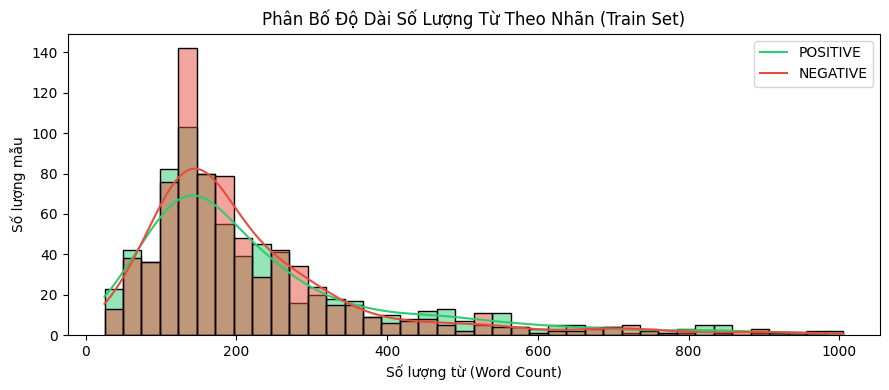

In [9]:
# Chuyển đổi sang pandas để phân tích nhanh
df_train = pd.DataFrame(imdb_dataset["train"])
df_train["char_length"] = df_train["text"].apply(len)
df_train["word_count"] = df_train["text"].apply(lambda t: len(t.split()))

print("--- 1. Kiểm Tra Phân Bố Nhãn (Class Balance) ---")
print(df_train["label"].value_counts().rename(index={0: "NEGATIVE (0)", 1: "POSITIVE (1)"}))

print("\n--- 2. Thống Kê Số Lượng Từ Trong Nhận Xét (Word Count Statistics) ---")
print(df_train["word_count"].describe())

# Trực quan hóa phân bố độ dài từ
plt.figure(figsize=(9, 4))
sns.histplot(data=df_train, x="word_count", hue="label", bins=40, kde=True, palette=["#e74c3c", "#2ecc71"])
plt.title("Phân Bố Độ Dài Số Lượng Từ Theo Nhãn (Train Set)")
plt.xlabel("Số lượng từ (Word Count)")
plt.ylabel("Số lượng mẫu")
plt.legend(["POSITIVE", "NEGATIVE"])
plt.tight_layout()
plt.show()


## 6. Exercise 2: Tiền Xử Lý & Mã Hóa Văn Bản (Tokenization & Dynamic Padding)
> Khởi tạo tokenizer cho mô hình nền `distilbert-base-uncased`, loại bỏ các thẻ HTML dư thừa (như `<br />`), cắt ngắn các câu vượt quá 256 tokens và sử dụng `DataCollatorWithPadding` để đệm linh hoạt theo từng batch.


In [10]:
pretrained_model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name)

def clean_and_tokenize(batch):
    # Loại bỏ thẻ HTML và khoảng trắng thừa
    cleaned_texts = [re.sub(r"<[^>]+>", "", text).strip() for text in batch["text"]]
    return tokenizer(cleaned_texts, truncation=True, max_length=256)

print("Đang tiến hành mã hóa tokenization theo batch...")
tokenized_datasets = imdb_dataset.map(clean_and_tokenize, batched=True, remove_columns=["text"])
print("Các trường tensor sau xử lý:", tokenized_datasets["train"].column_names)

# Khởi tạo collator thực hiện đệm động (dynamic padding)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


Đang tiến hành mã hóa tokenization theo batch...


Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Các trường tensor sau xử lý: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


## 7. Cổng Kiểm Tra Sanity Overfit 1 Batch (TDD Guard Gate)
> **Quy định bắt buộc theo `AGENTS.md` (§1.4):** Trước khi huấn luyện diện rộng, mô hình phải vượt qua bài test ép overfit 1 mini-batch nhỏ (8 mẫu) kéo loss về sát 0 để chứng minh tính học được (learnability) của kiến trúc và optimizer.


In [11]:
# Khởi tạo mô hình phân loại nhị phân
model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
).to(DEVICE)

# Tạo 1 mini-batch nhỏ (8 mẫu phân cực rõ ràng)
sanity_texts = [
    "An absolute masterpiece of filmmaking, thoroughly enjoyable!",
    "Terrible movie, completely unwatchable and boring.",
    "Outstanding acting performance and brilliant screenplay.",
    "Total garbage, waste of time and money.",
    "I loved every single second of this heartwarming film.",
    "Horrendous experience, dreadful directing and bad cast.",
    "Incredible cinematic achievement with breathtaking music.",
    "Dull, lifeless, and filled with ridiculous cliches."
]
sanity_labels = torch.tensor([1, 0, 1, 0, 1, 0, 1, 0], dtype=torch.long).to(DEVICE)
sanity_inputs = tokenizer(sanity_texts, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
sanity_inputs["labels"] = sanity_labels

# Ép học overfit qua AdamW
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
model.train()
print("Đang chạy kiểm tra Sanity Overfit 1-batch...")

for step in range(25):
    optimizer.zero_grad()
    outputs = model(**sanity_inputs)
    loss = outputs.loss
    loss.backward()
    optimizer.step()
    if (step + 1) % 5 == 0:
        print(f"Step {step+1:02d}/25 - Loss: {loss.item():.4f}")

assert loss.item() < 0.05, f"Lỗi: Loss={loss.item()} chưa đạt ngưỡng < 0.05!"
print(f"=> [SANITY GATE PASSED] Mô hình học mượt mà! Loss cuối: {loss.item():.4f} < 0.05")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đang chạy kiểm tra Sanity Overfit 1-batch...
Step 05/25 - Loss: 0.3069
Step 10/25 - Loss: 0.0370
Step 15/25 - Loss: 0.0088
Step 20/25 - Loss: 0.0026
Step 25/25 - Loss: 0.0015
=> [SANITY GATE PASSED] Mô hình học mượt mà! Loss cuối: 0.0015 < 0.05


## 8. Huấn Luyện Tinh Chỉnh Mô Hình (Finetuning With Trainer)
> Thiết lập `TrainingArguments` với tốc độ học `2e-5`, bộ tối ưu hóa AdamW, cơ chế lưu checkpoint tốt nhất theo `accuracy` và huấn luyện 2 epochs với chế độ Mixed Precision (FP16).


In [12]:
# Định nghĩa hàm tính toán metrics
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_metric.compute(predictions=preds, references=labels)["accuracy"]
    f1 = f1_metric.compute(predictions=preds, references=labels, average="macro")["f1"]
    prec = precision_metric.compute(predictions=preds, references=labels, average="macro")["precision"]
    rec = recall_metric.compute(predictions=preds, references=labels, average="macro")["recall"]
    return {
        "accuracy": float(acc),
        "macro_f1": float(f1),
        "macro_precision": float(prec),
        "macro_recall": float(rec)
    }

# Khởi tạo mô hình mới cho quá trình huấn luyện chính
model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
)

checkpoint_dir = Path("labs/lab03/outputs/checkpoints") if Path("labs/lab03").exists() else Path("../outputs/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

training_args = TrainingArguments(
    output_dir=str(checkpoint_dir),
    learning_rate=2e-5,
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=20,
    weight_decay=0.01,
    logging_steps=25,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=RANDOM_SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

print("Bắt đầu quá trình finetuning...")
train_result = trainer.train()
print("\nQuá trình huấn luyện hoàn tất!")
print(f"Tổng thời gian: {train_result.metrics['train_runtime']:.2f}s | Tốc độ: {train_result.metrics['train_samples_per_second']:.2f} mẫu/s")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Bắt đầu quá trình finetuning...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.437810,0.352921,0.848000,0.845779,0.856535,0.844185
2,0.270264,0.335021,0.866000,0.865483,0.866292,0.865017


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Quá trình huấn luyện hoàn tất!
Tổng thời gian: 51.71s | Tốc độ: 58.01 mẫu/s


## 9. Đánh Giá Hiệu Năng Trên Tập Test & Vẽ Ma Trận Nhầm Lẫn
> Đánh giá mô hình đã tinh chỉnh trên 1,000 mẫu tập Test độc lập, trích xuất bộ chỉ số đo lường toàn diện và vẽ biểu đồ Heatmap Ma trận nhầm lẫn (Confusion Matrix).


Đang đánh giá mô hình trên tập Test...


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Macro Precision,Macro Recall
0.270264,0.336344,2,0.865000,0.864999,0.865689,0.865571



--- BẢNG ĐO LƯỜNG ĐỊNH LƯỢNG TRÊN TẬP TEST ---
Test Loss:            0.3363
Test Accuracy:        86.50% (Ngưỡng đạt: >= 85.0%)
Test Macro F1:        86.50% (Ngưỡng đạt: >= 85.0%)
Test Macro Precision: 86.57%
Test Macro Recall:    86.56%


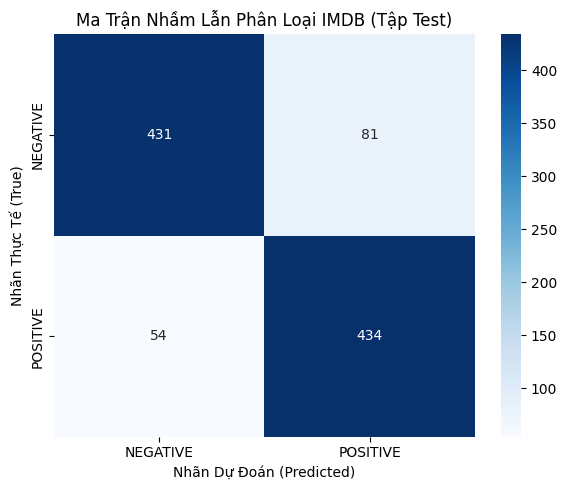


--- Báo Cáo Phân Loại Chi Tiết (Classification Report) ---
              precision    recall  f1-score   support

    NEGATIVE     0.8887    0.8418    0.8646       512
    POSITIVE     0.8427    0.8893    0.8654       488

    accuracy                         0.8650      1000
   macro avg     0.8657    0.8656    0.8650      1000
weighted avg     0.8662    0.8650    0.8650      1000



In [13]:
from sklearn.metrics import confusion_matrix, classification_report

# Đánh giá trên tập test
print("Đang đánh giá mô hình trên tập Test...")
test_metrics = trainer.evaluate(tokenized_datasets["test"])

print("\n--- BẢNG ĐO LƯỜNG ĐỊNH LƯỢNG TRÊN TẬP TEST ---")
print(f"Test Loss:            {test_metrics['eval_loss']:.4f}")
print(f"Test Accuracy:        {test_metrics['eval_accuracy'] * 100:.2f}% (Ngưỡng đạt: >= 85.0%)")
print(f"Test Macro F1:        {test_metrics['eval_macro_f1'] * 100:.2f}% (Ngưỡng đạt: >= 85.0%)")
print(f"Test Macro Precision: {test_metrics['eval_macro_precision'] * 100:.2f}%")
print(f"Test Macro Recall:    {test_metrics['eval_macro_recall'] * 100:.2f}%")

# Lấy nhãn dự đoán để vẽ Confusion Matrix
predictions = trainer.predict(tokenized_datasets["test"])
y_pred = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["NEGATIVE", "POSITIVE"], yticklabels=["NEGATIVE", "POSITIVE"])
plt.xlabel("Nhãn Dự Đoán (Predicted)")
plt.ylabel("Nhãn Thực Tế (True)")
plt.title("Ma Trận Nhầm Lẫn Phân Loại IMDB (Tập Test)")
plt.tight_layout()
plt.show()

print("\n--- Báo Cáo Phân Loại Chi Tiết (Classification Report) ---")
print(classification_report(y_true, y_pred, target_names=["NEGATIVE", "POSITIVE"], digits=4))


## 10. Tải Lại Checkpoint Mô Hình & Kiểm Chứng Dự Đoán
> Lưu mô hình tốt nhất vào thư mục `finetuned_distilbert`, tải lại từ đĩa để kiểm chứng khả năng phục hồi và dự đoán trên câu nhận xét mới, sau đó đóng gói toàn bộ thư mục `outputs/`.


In [14]:
# 1. Lưu mô hình và tokenizer đã tinh chỉnh
save_path = checkpoint_dir / "finetuned_distilbert"
trainer.save_model(str(save_path))
tokenizer.save_pretrained(str(save_path))
print(f"Đã lưu checkpoint mô hình tốt nhất vào: {save_path}")

# 2. Tải lại và kiểm chứng suy luận
loaded_tokenizer = AutoTokenizer.from_pretrained(str(save_path))
loaded_model = AutoModelForSequenceClassification.from_pretrained(str(save_path)).to(DEVICE)
loaded_model.eval()

new_review = "I was initially skeptical, but this film surprised me with its emotional depth and wonderful directing."
encoded_review = loaded_tokenizer(new_review, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    res_logits = loaded_model(**encoded_review).logits
    res_probs = torch.softmax(res_logits, dim=-1).squeeze()
    res_idx = torch.argmax(res_probs).item()

print(f"\nKiểm chứng nhận xét mới: '{new_review}'")
print(f"=> Dự đoán: {loaded_model.config.id2label[res_idx]} (Xác suất: {res_probs[res_idx].item()*100:.2f}%)")

# 3. Đóng gói artifacts nộp bài
outputs_folder = Path("labs/lab03/outputs") if Path("labs/lab03/outputs").exists() else Path("../outputs")
zip_target = outputs_folder.parent / "outputs_lab03"
shutil.make_archive(str(zip_target), "zip", str(outputs_folder))
print(f"\n[HOÀN THÀNH] Toàn bộ kết quả đã được nén tại: {zip_target}.zip")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu checkpoint mô hình tốt nhất vào: ..\outputs\checkpoints\finetuned_distilbert


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Kiểm chứng nhận xét mới: 'I was initially skeptical, but this film surprised me with its emotional depth and wonderful directing.'
=> Dự đoán: POSITIVE (Xác suất: 95.89%)

[HOÀN THÀNH] Toàn bộ kết quả đã được nén tại: ..\outputs_lab03.zip
